# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score, classification_report, confusion_matrix
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split

from sklearn.neighbors import NearestNeighbors

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [321]:
customer_data = pd.read_csv('shopping-data.csv')

In [322]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [323]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

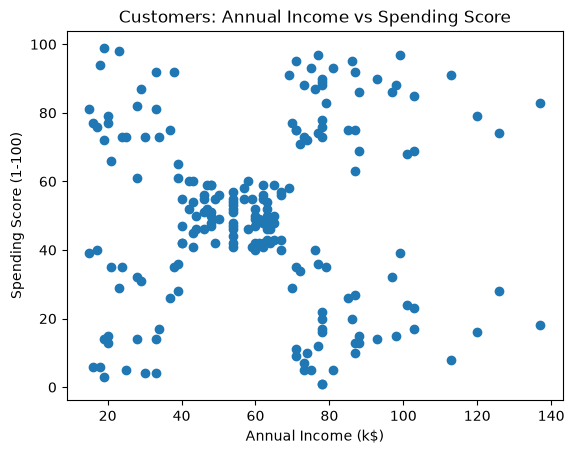

In [324]:
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customers: Annual Income vs Spending Score')
plt.show()

#### 3. Normalize the data

In [325]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X_customer = customer_data[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_customer)
pd.DataFrame(X_scaled, columns=features).describe().round(2)

,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


#### 4. Use Elbow method to decide number of clusters

    k  inertia  silhouette
0   1   400.00         NaN
1   2   269.69        0.32
2   3   157.70        0.47
3   4   108.92        0.49
4   5    65.57        0.55
5   6    55.06        0.54
6   7    44.86        0.53
7   8    37.23        0.46
8   9    32.39        0.46
9  10    29.98        0.44


C:\Users\kristupas.paulauskas\AppData\Local\Temp\ipykernel_22088\3912239953.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend()
C:\Users\kristupas.paulauskas\AppData\Local\Temp\ipykernel_22088\3912239953.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


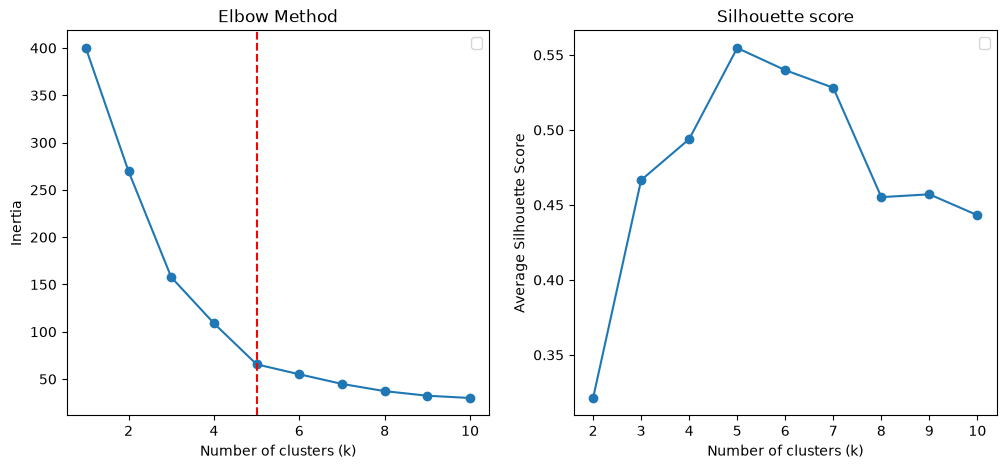

In [326]:
k_range = range(1, 11)
inertia = []
silhouette = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    if k > 1:
        silhouette.append(silhouette_score(X_scaled, labels))
    else:
        silhouette.append(np.nan)

print(pd.DataFrame({'k': k_range, 'inertia': inertia, 'silhouette': silhouette}).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(k_range, inertia, marker='o')
ax[0].axvline(5, color='r', linestyle='--')
ax[0].set_xlabel('Number of clusters (k)')
ax[0].set_ylabel('Inertia')
ax[0].set_title('Elbow Method')
ax[0].legend()

ax[1].plot(k_range, silhouette, marker='o')
ax[1].set_xlabel('Number of clusters (k)')
ax[1].set_ylabel('Average Silhouette Score')
ax[1].set_title('Silhouette score')
ax[1].legend()

#### 5. Perform Clustering using KMeans

In [327]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
customer_data['Cluster'] = kmeans.fit_predict(X_scaled)
customer_data.groupby('Cluster')[features].agg(['mean', 'count']).round(2)

Annual Income (k$)       Spending Score (1-100)      
                      mean count                   mean count
Cluster                                                      
0                    55.30    81                  49.52    81
1                    86.54    39                  82.13    39
2                    25.73    22                  79.36    22
3                    88.20    35                  17.11    35
4                    26.30    23                  20.91    23

#### 6. Plot scatter plot and color code in clustered groups

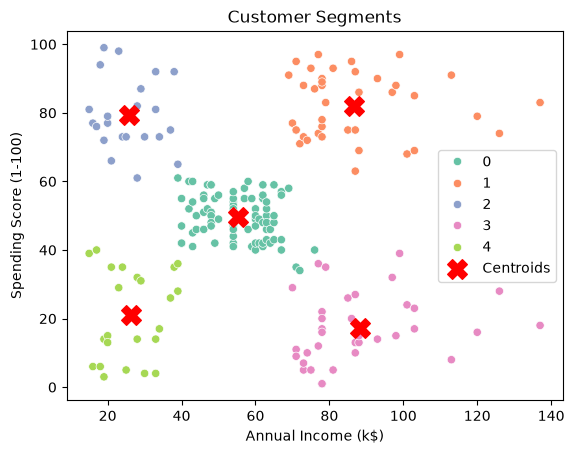

In [328]:
center = scaler.inverse_transform(kmeans.cluster_centers_)

sns.scatterplot(data=customer_data, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='Set2')
plt.scatter(center[:, 0], center[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segments')
plt.legend()
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

Heights [ 3.15  4.07  4.31  4.35  9.45 10.14 15.19 15.62]


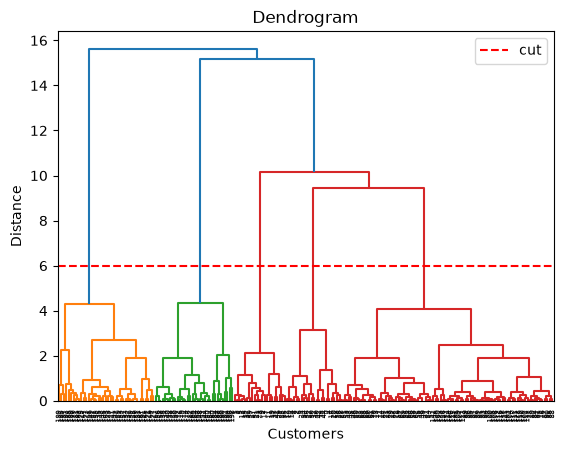

In [329]:
linked = linkage(X_scaled, method='ward')

print("Heights", np.round(linked[-8:, 2], 2))

dendogram = dendrogram(linked)
plt.axhline(y=6, color='r', linestyle='--', label='cut')
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.legend()

Optimal number of clusters is 5. I believe it's because of jump in merge height.

#### 8. Do clustering using Hierarchical Clustering

In [330]:
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
customer_data['HC_Cluster'] = hc.fit_predict(X_scaled)

print(customer_data.groupby('HC_Cluster')[features].agg(['mean', 'count']).round(2))
print(round(adjusted_rand_score(customer_data['Cluster'], customer_data['HC_Cluster']), 2))

           Annual Income (k$)       Spending Score (1-100)      
                         mean count                   mean count
HC_Cluster                                                      
0                       89.41    32                  15.59    32
1                       86.54    39                  82.13    39
2                       55.81    85                  49.13    85
3                       25.10    21                  80.05    21
4                       26.30    23                  20.91    23
0.94


#### 9. Plot scatter plot and color code in clustered groups

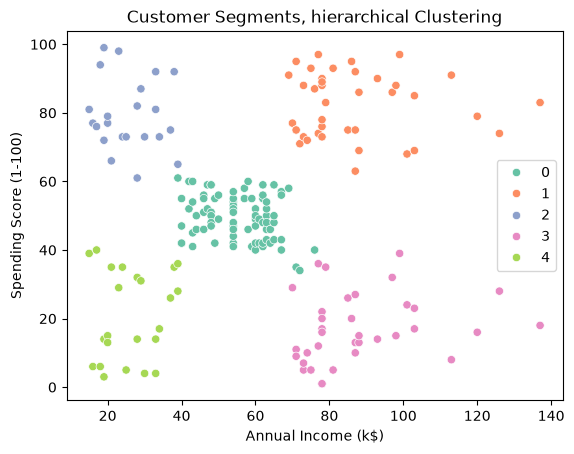

In [331]:
sns.scatterplot(data=customer_data, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='Set2')
plt.title('Customer Segments, hierarchical Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()

####  10. Do KMeans and DBSCAN clustering on this data

In [332]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

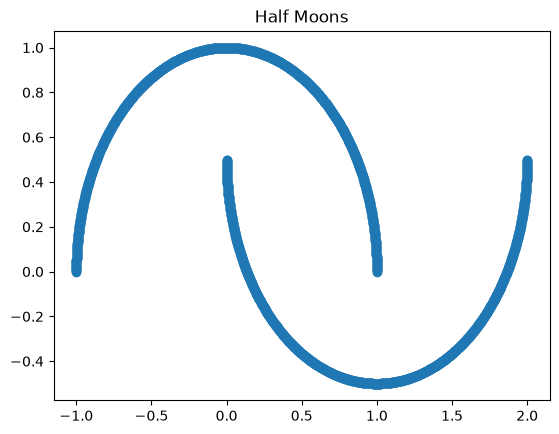

In [333]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [334]:
kmeans_moon = KMeans(n_clusters=2, n_init = 10, random_state = 42)
kmeans_moon_labels = kmeans_moon.fit_predict(moons_X)
print("Adjusted rand index", round(adjusted_rand_score(moon_y, kmeans_moon_labels), 3))

Adjusted rand index 0.254


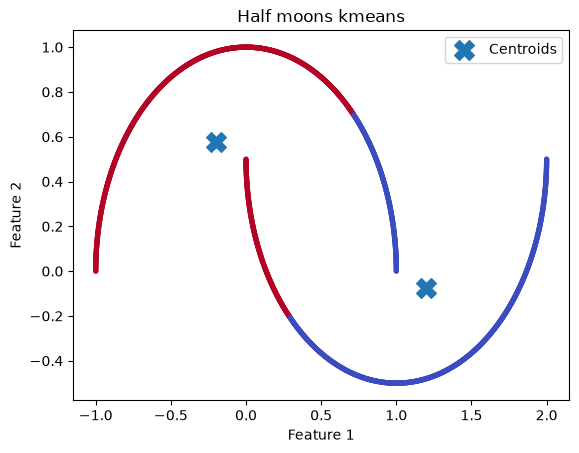

In [335]:
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=kmeans_moon_labels, cmap='coolwarm', s=8)
plt.scatter(kmeans_moon.cluster_centers_[:,0], kmeans_moon.cluster_centers_[:,1], marker='X', s=200, label = 'Centroids')

plt.title('Half moons kmeans')
plt.xlabel("Feature 1")
plt.ylabel('Feature 2')
plt.legend()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

Max k distance  0.0126


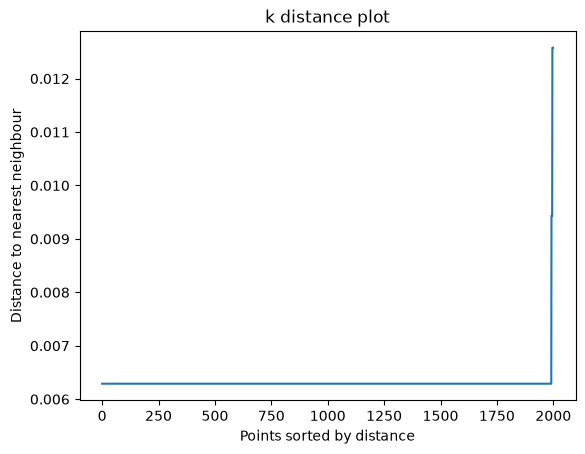

In [336]:
nn = NearestNeighbors(n_neighbors=5).fit(moons_X)
distances, _ = nn.kneighbors(moons_X)
k_dist = np.sort(distances[:, -1])

plt.plot(k_dist)
plt.title("k distance plot")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to nearest neighbour")
print("Max k distance ", round(k_dist.max(), 4))

In [337]:
rows = []
for eps in [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, .45, .5, .8]:
    for ms in [3,5,10,20]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(moons_X)
        rows.append({'eps': eps, 'min_samples' : ms, 'n_clusters': len(set(labels)) - (1 if -1 in labels else 0),
                     'n_noise': int((labels == -1).sum()), 'ARI': round(adjusted_rand_score(moon_y, labels), 3)})
grid = pd.DataFrame(rows)
print("Number of clusters found:")
grid.pivot(index='eps', columns='min_samples', values='n_clusters')

Number of clusters found:


min_samples,3,5,10,20
eps,,,,
0.005,2,0,0,0
0.010,2,2,0,0
0.020,2,2,2,0
0.050,2,2,2,2
0.100,2,2,2,2
0.200,2,2,2,2
0.300,2,2,2,2
0.450,2,2,2,2
0.500,2,2,2,2


In [338]:
print("Points labeled as noise:")
grid.pivot(index='eps', columns='min_samples', values='n_noise')

Points labeled as noise:


min_samples,3,5,10,20
eps,,,,
0.005,0,2000,2000,2000
0.010,0,0,2000,2000
0.020,0,0,0,2000
0.050,0,0,0,0
0.100,0,0,0,0
0.200,0,0,0,0
0.300,0,0,0,0
0.450,0,0,0,0
0.500,0,0,0,0


In [339]:
print("Rand index vs true labels:")
grid.pivot(index='eps', columns='min_samples', values='ARI')

Rand index vs true labels:


min_samples,3,5,10,20
eps,,,,
0.005,1.0,0.0,0.0,0.0
0.010,1.0,1.0,0.0,0.0
0.020,1.0,1.0,1.0,0.0
0.050,1.0,1.0,1.0,1.0
0.100,1.0,1.0,1.0,1.0
0.200,1.0,1.0,1.0,1.0
0.300,1.0,1.0,1.0,1.0
0.450,1.0,1.0,1.0,1.0
0.500,1.0,1.0,1.0,1.0


Text(0, 0.5, 'Feature 2')

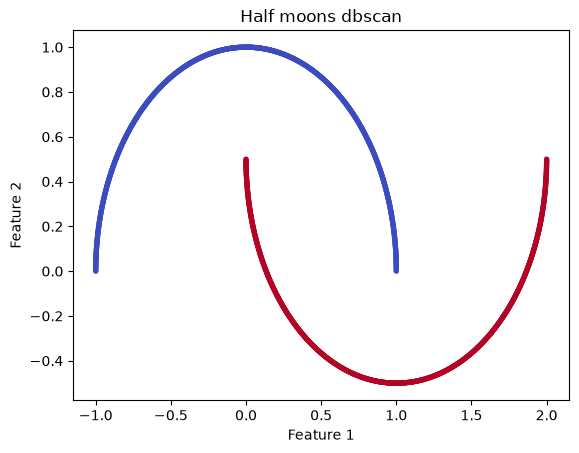

In [340]:
dbscan = DBSCAN(eps=.1, min_samples=5)
dbscan_labels = dbscan.fit_predict(moons_X)
plt.scatter(moons_X[:,0], moons_X[:, 1], c=dbscan_labels, cmap='coolwarm', s=8)
plt.title("Half moons dbscan")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

Kmeans splits data into two with roughly straight boundary, result dosen't follow real shape.

DBSCAN recovers both moons perfectly because we got ARI = 1. It was more sucsesful because it groups points by density.

For this dataset DBSCAN was more prefferable, because clusters are dense and very separated.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [341]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [342]:
print('Shape', penguins.shape)
penguins.info()
penguins.describe()

Shape (344, 5)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


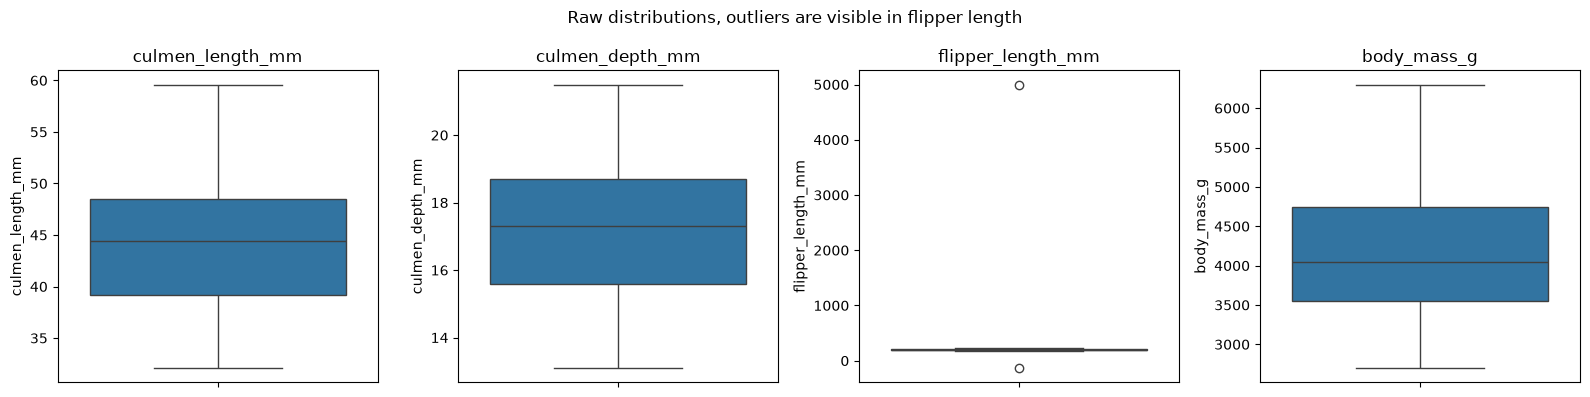

In [343]:
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=penguins[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel(col)
plt.suptitle('Raw distributions, outliers are visible in flipper length')
plt.tight_layout()
plt.show()

#### Based on dataframe describe, in own words explain any abnormal characteristics 

Missing values: the numeric columns have count = 342, while the dataset has 344 rows, so 2 rows are missing measurements. sex has only 335 not missing values.

flipper_length_mm is clearly bad: min = -132 a negative length is impossible.

sex has 3 unique values instead of 2: apart from MALE and FEMALE there is also a dot.

#### 14. Explore corrupted data

In [344]:
# find missing values. print entries with missing values, provide shape
print('Missing values per column:')
print(penguins.isna().sum(), '\n')

missing_rows = penguins[penguins.isna().any(axis=1)]
print('Rows with at least one missing value, shape:', missing_rows.shape)
missing_rows

Missing values per column:
culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64 

Rows with at least one missing value, shape: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [345]:
# Examine sex column
print(penguins['sex'].value_counts(dropna=False), '\n')

invalid_sex_rows = penguins[~penguins['sex'].isin(['MALE', 'FEMALE'])]
print('Rows where sex is not MALE or FEMALE, shape:', invalid_sex_rows.shape)
invalid_sex_rows

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64 

Rows where sex is not MALE or FEMALE, shape: (10, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,.
339,NaN,NaN,NaN,NaN,NaN


In [346]:
# find any unusual values. Print anomal rows
Q1 = penguins[num_cols].quantile(0.25)
Q3 = penguins[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(pd.DataFrame({'lower bound': lower, 'upper bound': upper}).round(1), '\n')

anomal_mask = ((penguins[num_cols] < lower) | (penguins[num_cols] > upper)).any(axis=1)
anomal_rows = penguins[anomal_mask]
print('Anomalous rows - shape:', anomal_rows.shape)
anomal_rows

                   lower bound  upper bound
culmen_length_mm          25.3         62.4
culmen_depth_mm           11.0         23.3
flipper_length_mm        154.4        249.4
body_mass_g             1750.0       6550.0 

Anomalous rows - shape: (2, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [347]:
# clean
penguins_clean = penguins.dropna(subset=num_cols)
penguins_clean = penguins_clean.drop(index=anomal_rows.index)
penguins_unknown_sex = penguins_clean[~penguins_clean['sex'].isin(['MALE', 'FEMALE'])].copy()
penguins_valid = penguins_clean[penguins_clean['sex'].isin(['MALE', 'FEMALE'])].reset_index(drop=True)

print(penguins_valid['sex'].value_counts())
penguins_valid.head()

sex
MALE      167
FEMALE    165
Name: count, dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


In [348]:
# scale numerical columns. assign to a variable X_penguins
scaler_penguins = StandardScaler()
X_penguins = scaler_penguins.fit_transform(penguins_valid[num_cols])
print('X_penguins shape:', X_penguins.shape)
pd.DataFrame(X_penguins, columns=num_cols).describe().round(2)


X_penguins shape: (332, 4)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,332.00,332.00,332.00,332.00
mean,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00
min,-2.19,-2.07,-2.07,-1.87
25%,-0.83,-0.79,-0.78,-0.82
50%,0.12,0.08,-0.28,-0.23
75%,0.85,0.79,0.86,0.71
max,2.86,2.22,2.14,2.60


In [349]:
# assign categorical column to a variable y_penguins
y_penguins = penguins_valid['sex']
print('y_penguins shape:', y_penguins.shape)
y_penguins.value_counts()

y_penguins shape: (332,)


sex
MALE      167
FEMALE    165
Name: count, dtype: int64

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

All values missing values were dropped because there is nothing to work with.

Impossible flipper length -132 mm and 5m dropped.

Sex unknown NA or . were removed from the training data.

Cons:

We lose a bit of information.

Pros:

Sex classes remain balanced.

Every remaining value is real


#### 16. Perform PCA with 2 components. Plot the results 

Explained variance ratio: [0.687 0.196] | total: 0.884


Text(0, 0.5, 'PC2 of variance')

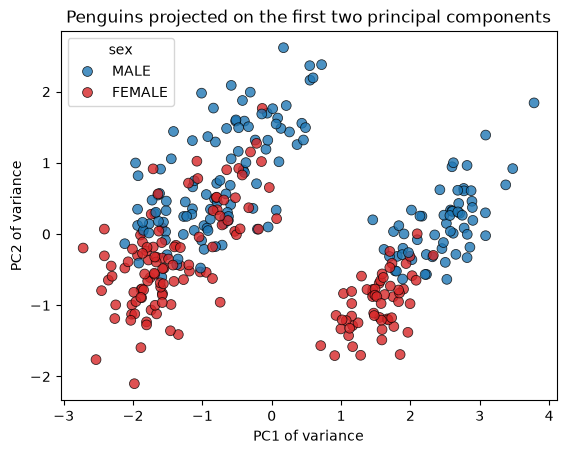

In [350]:
pca_2 = PCA(n_components=2)
X_penguins_pca = pca_2.fit_transform(X_penguins)

print('Explained variance ratio:', pca_2.explained_variance_ratio_.round(3),
      '| total:', round(pca_2.explained_variance_ratio_.sum(), 3))

pca_df = pd.DataFrame(X_penguins_pca, columns=['PC1', 'PC2'])
pca_df['sex'] = y_penguins.values

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='sex', palette={'MALE': 'tab:blue', 'FEMALE': 'tab:red'},
                s=50, alpha=0.8, edgecolor='k')
plt.title('Penguins projected on the first two principal components')
plt.xlabel('PC1 of variance')
plt.ylabel("PC2 of variance")

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

     eigenvalue  explained variance  cumulative
PC1       2.757               0.687       0.687
PC2       0.788               0.196       0.884
PC3       0.359               0.090       0.973
PC4       0.108               0.027       1.000


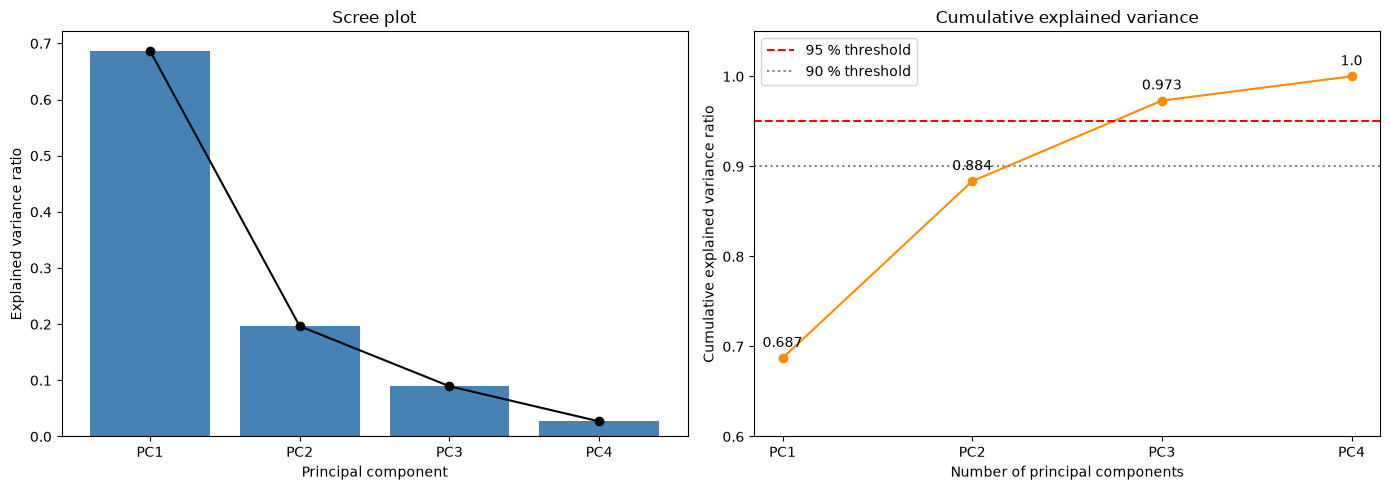

In [351]:
pca_full = PCA().fit(X_penguins)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
pcs = [f'PC{i}' for i in range(1, len(evr) + 1)]

print(pd.DataFrame({'eigenvalue': pca_full.explained_variance_.round(3),
                    'explained variance': evr.round(3),
                    'cumulative': cum_evr.round(3)}, index=pcs))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(pcs, evr, color='steelblue', label='individual')
ax[0].plot(pcs, evr, marker='o', color='black')
ax[0].set_title('Scree plot')
ax[0].set_xlabel('Principal component')
ax[0].set_ylabel('Explained variance ratio')

ax[1].plot(pcs, cum_evr, marker='o', color='darkorange')
ax[1].axhline(0.95, color='red', linestyle='--', label='95 % threshold')
ax[1].axhline(0.90, color='grey', linestyle=':', label='90 % threshold')
for x, y in zip(pcs, cum_evr):
    ax[1].annotate(round(y, 3), (x, y), textcoords='offset points', xytext=(0, 8), ha='center')
ax[1].set_ylim(0.6, 1.05)
ax[1].set_title('Cumulative explained variance')
ax[1].set_xlabel('Number of principal components')
ax[1].set_ylabel('Cumulative explained variance ratio')
ax[1].legend()
plt.tight_layout()
plt.show()

#### 18. Calculate (show in numbers) and display component loadings

In [352]:
# Component loadings (how much each original feature contributes to each PC)
weights = pd.DataFrame(pca_full.components_.T, index=num_cols, columns=pcs)
print('Weights (eigenvectors):')
print(weights.round(3), '\n')

loadings = weights * np.sqrt(pca_full.explained_variance_)
print('Loadings (correlation feature PC):')
print(loadings.round(3))

Weights (eigenvectors):
                     PC1    PC2    PC3    PC4
culmen_length_mm   0.453  0.605  0.638 -0.148
culmen_depth_mm   -0.399  0.793 -0.431  0.162
flipper_length_mm  0.577  0.004 -0.232  0.783
body_mass_g        0.550  0.072 -0.595 -0.582 

Loadings (correlation feature PC):
                     PC1    PC2    PC3    PC4
culmen_length_mm   0.752  0.537  0.382 -0.049
culmen_depth_mm   -0.662  0.704 -0.259  0.053
flipper_length_mm  0.958  0.003 -0.139  0.257
body_mass_g        0.914  0.064 -0.356 -0.191


Text(50.385633680555536, 0.5, 'Original feature')

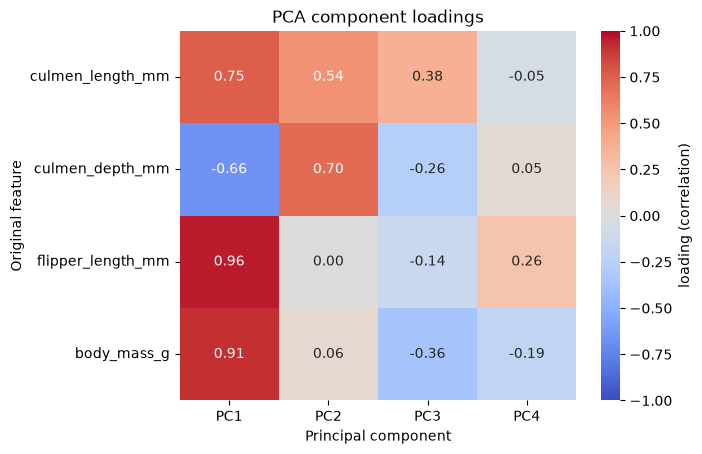

In [353]:
# show heatmap
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'loading (correlation)'})
plt.title('PCA component loadings')
plt.xlabel('Principal component')
plt.ylabel('Original feature')

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [354]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size=0.25, stratify=y_penguins, random_state=42)

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)

print('Train size:', X_train.shape[0], ' test size:', X_test.shape[0])
print('Test accuracy (2 PCs):', round(accuracy_score(y_test, y_pred), 3), '\n')
print(classification_report(y_test, y_pred))

Train size: 249  test size: 83
Test accuracy (2 PCs): 0.855 

              precision    recall  f1-score   support

      FEMALE       0.89      0.80      0.85        41
        MALE       0.83      0.90      0.86        42

    accuracy                           0.86        83
   macro avg       0.86      0.85      0.85        83
weighted avg       0.86      0.86      0.86        83



#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [355]:
# 1. take entries from original data with sex unknown, scale numerical columns
print('Entries with unknown sex:', penguins_unknown_sex.shape)
display(penguins_unknown_sex)

X_unknown_scaled = scaler_penguins.transform(penguins_unknown_sex[num_cols])


Entries with unknown sex: (8, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,.


In [356]:
# 2. apply the same PCA transformation to the new data
N_COMPONENTS = 3 
pca_final = PCA(n_components=N_COMPONENTS).fit(X_penguins)

X_unknown_pca = pca_final.transform(X_unknown_scaled)
pd.DataFrame(X_unknown_pca, columns=[f'PC{i+1}' for i in range(N_COMPONENTS)], index=penguins_unknown_sex.index).round(3)

,PC1,PC2,PC3
8,-1.847,-0.786,-0.699
10,-1.743,-0.798,0.200
11,-1.757,-0.683,-0.040
47,-2.645,-0.133,0.124
246,1.166,-1.108,0.515
286,1.581,-0.830,0.319
324,1.929,-0.944,0.492
336,1.452,-0.471,-0.382


In [357]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
X_train_full = pca_final.transform(X_penguins)
y_train_full = y_penguins

# Train a classifier
final_model = LogisticRegression()
final_model.fit(X_train_full, y_train_full)
print('Training accuracy on all valid data:', round(final_model.score(X_train_full, y_train_full), 3))

Training accuracy on all valid data: 0.883


In [358]:
# 4. Make predictions on the new data. Display the features and predicted values
predictions = penguins_unknown_sex[num_cols].copy()
predictions['original_sex'] = penguins_unknown_sex['sex'].fillna('NaN')
predictions['predicted_sex'] = final_model.predict(X_unknown_pca)
predictions['P(MALE)'] = final_model.predict_proba(X_unknown_pca)[:, list(final_model.classes_).index('MALE')].round(3)
predictions

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,original_sex,predicted_sex,P(MALE)
8,34.1,18.1,193.0,3475.0,NaN,FEMALE,0.195
10,37.8,17.1,186.0,3300.0,NaN,FEMALE,0.021
11,37.8,17.3,180.0,3700.0,NaN,FEMALE,0.055
47,37.5,18.9,179.0,2975.0,NaN,FEMALE,0.093
246,44.5,14.3,216.0,4100.0,NaN,FEMALE,0.024
286,46.2,14.4,214.0,4650.0,NaN,FEMALE,0.107
324,47.3,13.8,216.0,4725.0,NaN,FEMALE,0.063
336,44.5,15.7,217.0,4875.0,.,MALE,0.677


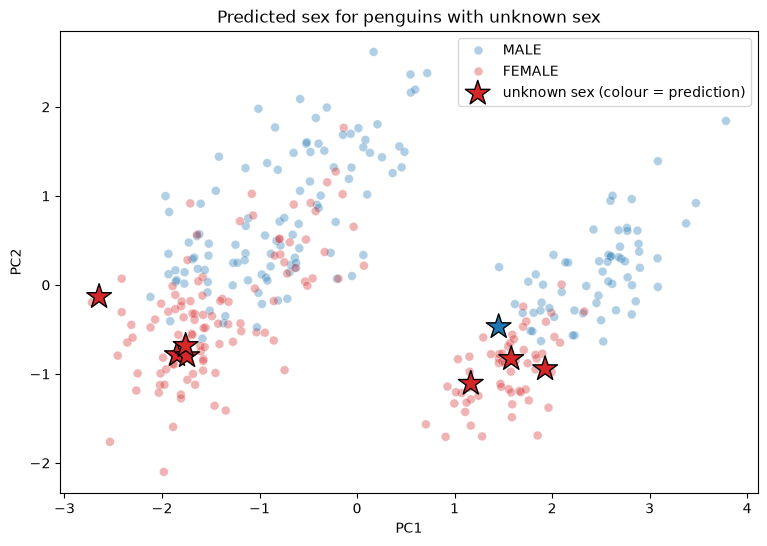

In [ ]:
train_plot = pd.DataFrame(X_train_full[:, :2], columns=['PC1', 'PC2'])
train_plot['sex'] = y_train_full.values

sns.scatterplot(data=train_plot, x='PC1', y='PC2', hue='sex', palette={'MALE': 'tab:blue', 'FEMALE': 'tab:red'},alpha=0.35, s=40)
colors = predictions['predicted_sex'].map({'MALE': 'tab:blue', 'FEMALE': 'tab:red'})
plt.scatter(X_unknown_pca[:, 0], X_unknown_pca[:, 1], c=colors, marker='*', s=350, edgecolor='black',
            label='unknown sex')
plt.title('Predicted sex for unknown')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()